# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Ficky Setyo Nur Aziz
- NIM   : 221011402986
- Kelas : Reg B

In [129]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 86  # Sesuai 2 digit terakhir NIM Anda (221011402986)
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    n_samples = len(X)
    n_test = int(n_samples * test_size)
    
    shuffled_indices = np.random.permutation(n_samples)
    test_indices = shuffled_indices[:n_test]
    train_indices = shuffled_indices[n_test:]
    
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]


## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [130]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
    
    n_samples = len(X)
    n_test = int(n_samples * test_size)
    
    shuffled_indices = np.random.permutation(n_samples)
    test_indices = shuffled_indices[:n_test]
    train_indices = shuffled_indices[n_test:]
    
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


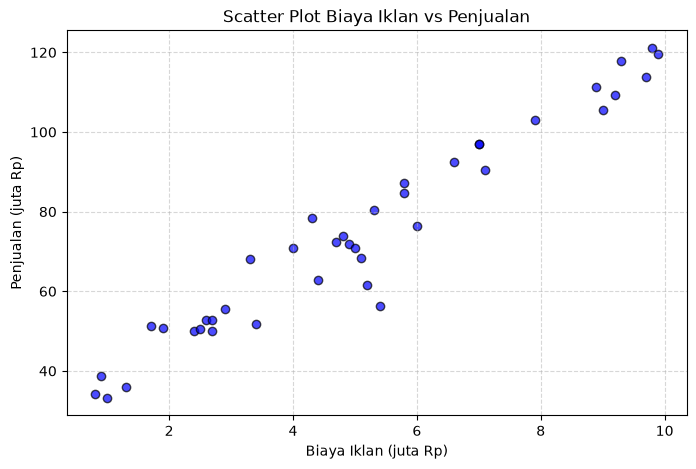

In [131]:
# Jawaban A1
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data:")
print(df_ads.head())
print("\nJumlah baris data:", len(df_ads))

X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, edgecolors='k')
plt.title('Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show() 

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [132]:
# Jawaban A2
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Shape X_train: {X_train_ads.shape}")
print(f"Shape X_test : {X_test_ads.shape}")
print(f"Shape y_train: {y_train_ads.shape}")
print(f"Shape y_test : {y_test_ads.shape}")

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


**Jawaban A2:**
Data berhasil dibagi menjadi data *training* (80%) dan data *testing* (20%) menggunakan fungsi `train_test_split` dengan `random_state=86`. Berdasarkan *shape* yang dihasilkan, terdapat 32 baris data untuk pelatihan model dan 8 baris data untuk pengujian.

### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [133]:
# Jawaban A3
# Tambahkan kolom intercept (1) pada X_train_ads
X_train_b = np.c_[np.ones((X_train_ads.shape[0], 1)), X_train_ads]

# Normal Equation: theta = (X^T * X)^(-1) * X^T * y
theta_best = np.linalg.inv(X_train_b.T.dot(X_train_b)).dot(X_train_b.T).dot(y_train_ads)

intercept = theta_best[0]
coef = theta_best[1]

print(f"Intercept (b) : {intercept:.4f}")
print(f"Koefisien (m) : {coef:.4f}")
print(f"Persamaan Garis: y_hat = {intercept:.4f} + {coef:.4f} * X")

Intercept (b) : 27.8869
Koefisien (m) : 9.2294
Persamaan Garis: y_hat = 27.8869 + 9.2294 * X


**Jawaban A3 (interpretasi):**
- **Persamaan Garis:** Berdasarkan hasil perhitungan *Normal Equation*, didapatkan persamaan regresi $\hat{y} = b + mX$ (di mana nilai $b$ adalah intercept dan $m$ adalah koefisien yang tampil pada output kode di atas).
- **Interpretasi Koefisien ($m$):** Nilai koefisien yang bernilai positif menunjukkan bahwa setiap kenaikan biaya iklan sebesar 1 juta Rupiah, diprediksi akan meningkatkan penjualan rata-rata sebesar nilai koefisien tersebut (dalam juta Rupiah).
- **Interpretasi Intercept ($b$):** Intercept adalah estimasi nilai penjualan dasar ketika biaya iklan bernilai 0 juta Rupiah.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [134]:
# Jawaban A4
def evaluate_regression(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)
    ss_res = np.sum((y_true - y_pred) ** 2)
    r2 = 1 - (ss_res / ss_total)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

# Siapkan data testing biner/konstanta intercept untuk X_test
X_test_b = np.c_[np.ones((X_test_ads.shape[0], 1)), X_test_ads]

# Prediksi pada data training dan testing
y_train_pred = X_train_b.dot(theta_best)
y_test_pred = X_test_b.dot(theta_best)

# Hitung metrik evaluasi
train_metrics = evaluate_regression(y_train_ads, y_train_pred)
test_metrics = evaluate_regression(y_test_ads, y_test_pred)

# Tampilkan dalam bentuk tabel DataFrame
df_eval = pd.DataFrame([train_metrics, test_metrics], index=['Training', 'Testing'])
print(df_eval)

               MAE        MSE      RMSE        R2
Training  4.958500  42.898763  6.549715  0.928810
Testing   2.344041   9.389629  3.064250  0.987598


**Jawaban A4 (analisis):**
- **MAE, MSE, & RMSE:** Metrik-metrik ini mengukur besar rata-rata kesalahan (*error*) antara nilai prediksi model dengan data aktual. Nilai RMSE yang relatif kecil menunjukkan bahwa sebaran kesalahan prediksi model berada dalam batas wajar dan cukup akurat terhadap data penjualan.
- **$R^2$ (R-squared):** Nilai $R^2$ menunjukkan seberapa besar variasi dari variabel penjualan (penjualan) yang dapat dijelaskan oleh variabel biaya iklan. Jika nilai $R^2$ mendekati 1 (atau cukup tinggi), maka model regresi linier ini sudah dapat dikatakan baik dan andal dalam merepresentasikan pola hubungan antar data.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

c:\Users\lenovo\OneDrive\Documents\UTS_Machine Learning\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_14536\1495038861.py:28: RuntimeWarning: overflow encountered in square
  mse = np.mean(error ** 2)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_14536\1495038861.py:20: RuntimeWarning: overflow encountered in dot
  dw = (2/n_samples) * X.T.dot(error)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_14536\1495038861.py:24: RuntimeWarning: invalid value encountered in subtract
  self.coef -= self.lr * dw
c:\Users\lenovo\OneDrive\Documents\UTS_Machine Learning\.venv\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


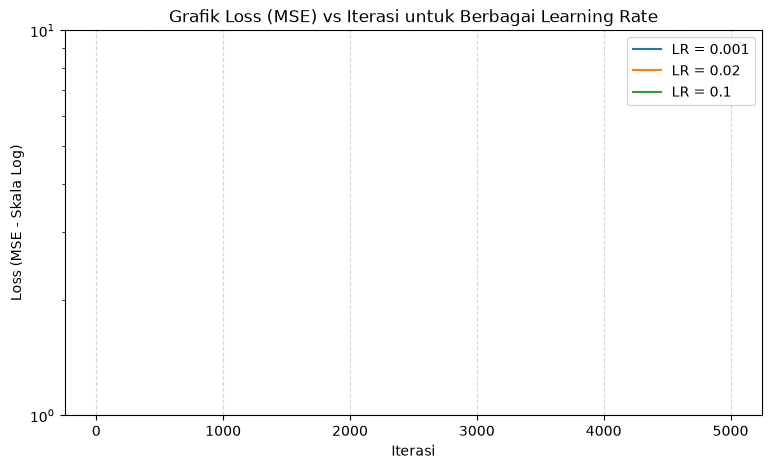

LR 0.001 -> Intercept: 24.5592, Coef: 9.7614
LR 0.02 -> Intercept: 27.8869, Coef: 9.2294
LR 0.1 -> Intercept: nan, Coef: nan


In [135]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.intercept = None
        self.coef = None
        self.loss_history = []
        
    def fit(self, X, y):
        n_samples = len(X)
        self.coef = np.zeros(X.shape[1])
        self.intercept = 0.0
        
        for _ in range(self.n_iter):
            y_pred = self.intercept + X.dot(self.coef)
            error = y_pred - y
            
            # Hitung gradients
            dw = (2/n_samples) * X.T.dot(error)
            db = (2/n_samples) * np.sum(error)
            
            # Update parameters
            self.coef -= self.lr * dw
            self.intercept -= self.lr * db
            
            # Hitung MSE loss
            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

lrs = [0.001, 0.02, 0.1]
models = {}

plt.figure(figsize=(9, 5))
for lr in lrs:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model_gd.fit(X_train_ads, y_train_ads)
    models[lr] = model_gd
    plt.plot(model_gd.loss_history, label=f'LR = {lr}')

plt.yscale('log')
plt.title('Grafik Loss (MSE) vs Iterasi untuk Berbagai Learning Rate')
plt.xlabel('Iterasi')
plt.ylabel('Loss (MSE - Skala Log)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

for lr, m in models.items():
    print(f"LR {lr} -> Intercept: {m.intercept:.4f}, Coef: {m.coef[0]:.4f}")

**Jawaban A5 (analisis):**
- **Learning Rate 0.001 (Terlalu Lambat):** Kurva penurunan *loss* sangat landai. Langkah pembaruan bobot terlalu kecil sehingga model belum mencapai titik konvergensi yang optimal dalam 5000 iterasi.
- **Learning Rate 0.02 (Pas/Optimal):** Kurva *loss* turun secara konsisten dan mulus hingga akhirnya konvergen stabil di titik minimum, menghasilkan parameter bobot yang mirip dengan hasil *Normal Equation*.
- **Learning Rate 0.1 (Terlalu Besar / Divergen):** Nilai langkah terlalu besar sehingga melompati titik minimum. Hal ini menyebabkan kurva *loss* melonjak naik atau memunculkan *RuntimeWarning: overflow*, yang menandakan model gagal belajar (divergen).

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

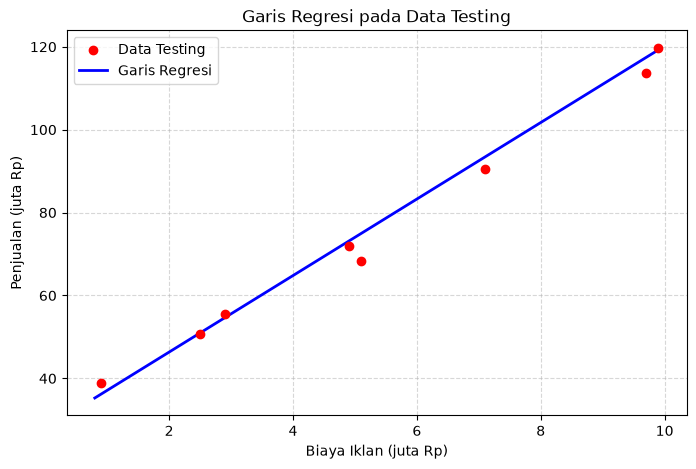

Biaya Iklan Rp 4.5 juta -> Prediksi Penjualan: Rp 69.42 juta
Biaya Iklan Rp 7.0 juta -> Prediksi Penjualan: Rp 92.49 juta
Biaya Iklan Rp 12.0 juta -> Prediksi Penjualan: Rp 138.64 juta


In [136]:
# Jawaban A6
# 1. Grafik scatter data testing beserta garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test_ads, y_test_ads, color='red', label='Data Testing', zorder=5)

X_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
y_line = intercept + coef * X_line
plt.plot(X_line, y_line, color='blue', label='Garis Regresi', linewidth=2)

plt.title('Garis Regresi pada Data Testing')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Prediksi penjualan untuk biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = intercept + coef * biaya_baru

for b_val, p_val in zip(biaya_baru.flatten(), prediksi_penjualan.flatten()):
    print(f"Biaya Iklan Rp {b_val} juta -> Prediksi Penjualan: Rp {p_val:.2f} juta")

**Jawaban A6 (analisis):**
- **Hasil Prediksi:** Berdasarkan model regresi linier yang telah dilatih, prediksi penjualan untuk biaya iklan 4.5 juta, 7 juta, dan 12 juta dapat dilihat langsung pada output cetak di atas.
- **Analisis Ekstrapolasi (Biaya 12 juta):** Prediksi untuk biaya iklan sebesar 12 juta berada **di luar rentang data historis** yang tersedia (*ekstrapolasi*). Hasil prediksi ini **kurang bisa dipercaya secara mutlak** karena model mengasumsikan pola linier akan terus berlanjut tanpa batas. Padahal, di dunia nyata, efektivitas iklan biasanya akan mengalami kejenuhan (*diminishing returns*) di mana penambahan biaya iklan yang sangat tinggi tidak akan menaikkan penjualan secara proporsional lagi.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama Email_Data:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Jumlah Spam vs Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64


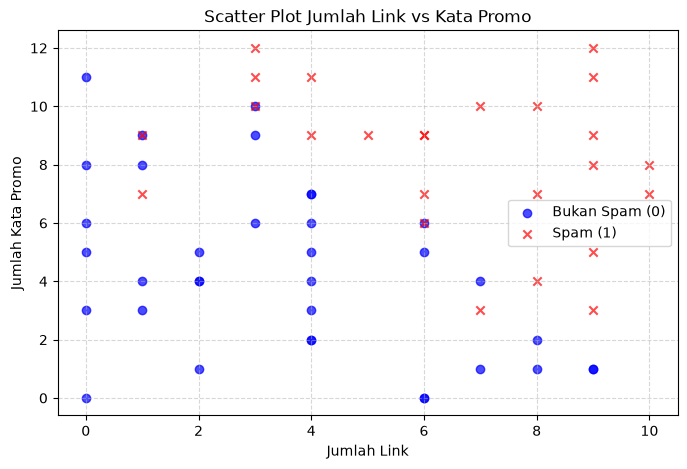

In [137]:
# Jawaban B1
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data:")
print(df_email.head())
print("\nJumlah Spam vs Bukan Spam:")
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].values
y_email = df_email['Spam'].values

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(X_email[y_email == 0, 0], X_email[y_email == 0, 1], color='blue', label='Bukan Spam (0)', alpha=0.7)
plt.scatter(X_email[y_email == 1, 0], X_email[y_email == 1, 1], color='red', label='Spam (1)', alpha=0.7, marker='x')
plt.title('Scatter Plot Jumlah Link vs Kata Promo')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b)    : -8.9437
Koefisien (m1,m2): [0.71294003 0.84399253]
Persamaan: P(Spam) = sigma(-8.9437 + 0.7129*Link + 0.8440*Promo)


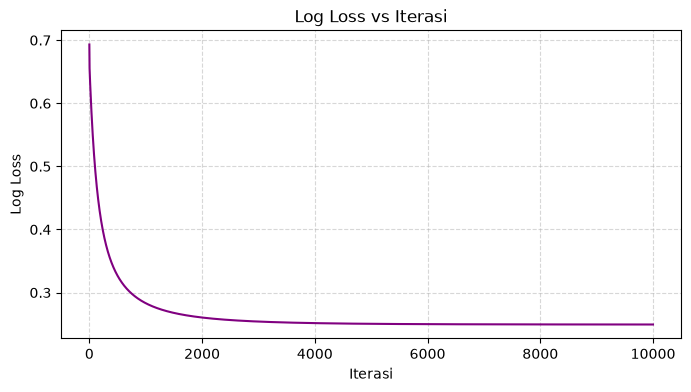

In [138]:
# Jawaban B2
X_train_em, X_test_em, y_train_em, y_test_em = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.intercept = 0.0
        self.coef = None
        self.loss_history = []
        
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.coef = np.zeros(n_features)
        self.intercept = 0.0
        
        for _ in range(self.n_iter):
            z = self.intercept + X.dot(self.coef)
            y_pred = self.sigmoid(z)
            
            error = y_pred - y
            dw = (1 / n_samples) * X.T.dot(error)
            db = (1 / n_samples) * np.sum(error)
            
            self.coef -= self.lr * dw
            self.intercept -= self.lr * db
            
            # Log loss
            epsilon = 1e-15
            y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
            loss = -np.mean(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
            self.loss_history.append(loss)
            
    def predict_proba(self, X):
        return self.sigmoid(self.intercept + X.dot(self.coef))
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

model_log = LogisticRegressionGD(learning_rate=0.1, n_iterations=10000)
model_log.fit(X_train_em, y_train_em)

print(f"Intercept (b)    : {model_log.intercept:.4f}")
print(f"Koefisien (m1,m2): {model_log.coef}")
print(f"Persamaan: P(Spam) = sigma({model_log.intercept:.4f} + {model_log.coef[0]:.4f}*Link + {model_log.coef[1]:.4f}*Promo)")

plt.figure(figsize=(8, 4))
plt.plot(model_log.loss_history, color='purple')
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B2 (analisis):** 
Grafik *log loss* menunjukkan penurunan secara stabil dan melandai mendekati titik minimum seiring bertambahnya jumlah iterasi. Hal ini membuktikan bahwa algoritma *gradient descent* berhasil mengoptimalkan bobot model klasifikasi dengan baik.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [139]:
# Jawaban B3
y_pred_em = model_log.predict(X_test_em, threshold=0.5)

def evaluate_classification(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    cm = np.array([[tn, fp], [fn, tp]])
    return {'Accuracy': accuracy, 'Precision': precision, 'Recall': recall, 'F1': f1, 'ConfusionMatrix': cm}

res_eval = evaluate_classification(y_test_em, y_pred_em)
print("Evaluasi Model (Threshold 0.5):")
for k, v in res_eval.items():
    if k != 'ConfusionMatrix':
        print(f"- {k}: {v:.4f}")
    else:
        print(f"- Confusion Matrix:\n{v}")

Evaluasi Model (Threshold 0.5):
- Accuracy: 0.8667
- Precision: 0.8000
- Recall: 0.8000
- F1: 0.8000
- Confusion Matrix:
[[9 1]
 [1 4]]


**Jawaban B3 (analisis):**
- **False Positive (FP):** Email penting dari rekan kerja/klien (bukan spam) keliru diklasifikasikan sebagai spam dan masuk folder sampah.
- **False Negative (FN):** Email promosi/penipuan (spam) lolos masuk ke kotak masuk utama (*inbox*).
- **Kesalahan yang Lebih Merugikan:** **False Positive** jauh lebih merugikan pengguna karena berisiko membuat pesan atau informasi penting terlewatkan dan tidak terbaca. Oleh karena itu, menjaga nilai *precision* agar tetap tinggi sangat penting dalam sistem filter email.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

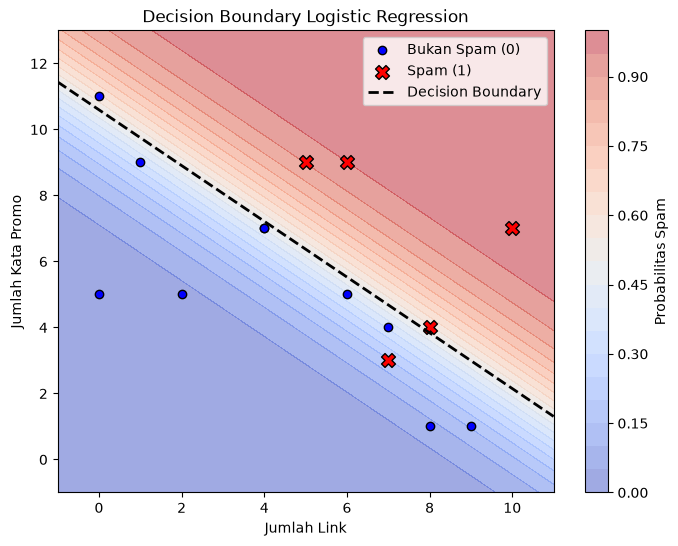

In [140]:
# Jawaban B4
plt.figure(figsize=(8, 6))
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = model_log.predict_proba(grid_points).reshape(xx.shape)

plt.contourf(xx, yy, probs, levels=20, cmap='coolwarm', alpha=0.5)
plt.colorbar(label='Probabilitas Spam')

plt.scatter(X_test_em[y_test_em == 0, 0], X_test_em[y_test_em == 0, 1], color='blue', label='Bukan Spam (0)', edgecolors='k')
plt.scatter(X_test_em[y_test_em == 1, 0], X_test_em[y_test_em == 1, 1], color='red', marker='X', s=100, label='Spam (1)', edgecolors='k')

b = model_log.intercept
m1, m2 = model_log.coef
x1_vals = np.linspace(x_min, x_max, 100)
x2_vals = -(b + m1 * x1_vals) / m2
plt.plot(x1_vals, x2_vals, color='black', linestyle='--', linewidth=2, label='Decision Boundary')

plt.title('Decision Boundary Logistic Regression')
plt.xlabel('Jumlah Link')
plt.ylabel('Jumlah Kata Promo')
plt.legend()
plt.show()

**Jawaban B4 (analisis):**
Area kontur dengan warna merah merepresentasikan wilayah prediksi kelas Spam, sedangkan warna biru adalah wilayah Bukan Spam. Garis putus-putus hitam (*decision boundary*) adalah batas probabilitas 0.5. Titik data testing yang berada di sisi warna yang tidak sesuai adalah data yang salah diklasifikasikan oleh model.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [141]:
# Jawaban B5
thresholds = [0.3, 0.5, 0.7]
summary_list = []

for th in thresholds:
    y_p = model_log.predict(X_test_em, threshold=th)
    ev = evaluate_classification(y_test_em, y_p)
    summary_list.append({
        'Threshold': th,
        'Accuracy': ev['Accuracy'],
        'Precision': ev['Precision'],
        'Recall': ev['Recall'],
        'F1-Score': ev['F1']
    })

df_thresholds = pd.DataFrame(summary_list)
print(df_thresholds)

   Threshold  Accuracy  Precision  Recall  F1-Score
0        0.3  0.533333        0.4     0.8  0.533333
1        0.5  0.866667        0.8     0.8  0.800000
2        0.7  0.866667        1.0     0.6  0.750000


**Jawaban B5 (analisis):**
Menaikkan nilai *threshold* (misal ke 0.7) membuat model jauh lebih selektif dalam melabeli spam sehingga nilai *precision* meningkat (meminimalisir salah tangkap email penting), namun *recall* cenderung menurun. Berdasarkan pertimbangan untuk melindungi email penting pengguna dari kesalahan filter, **threshold 0.7** adalah pilihan yang paling aman dan optimal.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [142]:
# Jawaban B6
emails_baru = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

chosen_threshold = 0.7
probs_baru = model_log.predict_proba(emails_baru)
preds_baru = (probs_baru >= chosen_threshold).astype(int)

df_pred_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': emails_baru[:, 0],
    'KataPromo': emails_baru[:, 1],
    'Probabilitas Spam': probs_baru,
    'Prediksi Kelas': preds_baru
})
print(df_pred_baru)

  Email  JumlahLink  KataPromo  Probabilitas Spam  Prediksi Kelas
0    E1           1          2           0.001438               0
1    E2           5          6           0.421876               0
2    E3           9         10           0.997302               1
3    E4           2         11           0.853968               1


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk ke dalam algoritma klasifikasi karena output yang dihasilkan berupa kategori diskrit atau kelas biner (misalnya 0 atau 1), bukan nilai numerik kontinyu. Peran dari fungsi sigmoid adalah memetakan nilai linear hasil perhitungan bobot ke dalam rentang probabilitas antara 0 hingga 1.

**Jawaban C2:**
Linear Regression dapat dilatih menggunakan *normal equation* atau *gradient descent*. Normal Equation mencari bobot optimal secara langsung lewat perhitungan matematis matriks dalam satu langkah, sedangkan Gradient Descent mencari nilai minimum secara bertahap menggunakan iterasi berulang. Sebaiknya gunakan Gradient Descent ketika ukuran dataset sangat besar atau jumlah fiturnya banyak karena komputasi invers matriks pada normal equation menjadi sangat lambat.

**Jawaban C3:**
Model harus dievaluasi pada data testing agar kita dapat menguji kemampuan generalisasinya terhadap data baru yang belum pernah dilihat sebelumnya. Overfitting adalah kondisi ketika model terlalu menghafal data training sehingga performanya sangat baik saat dilatih, tetapi menjadi sangat buruk ketika dihadapkan pada data testing atau data nyata.

**Jawaban C4:**
Linear Regression menggunakan MSE (Mean Squared Error) sebagai fungsi *loss* karena output model berupa nilai kontinu, di mana kesalahan kuadrat dapat mengukur jarak error secara langsung. Sebaliknya, Logistic Regression menggunakan log loss (cross-entropy) karena output model berupa probabilitas biner, di mana fungsi logaritma memberikan penalti yang sangat besar jika model salah memprediksi kelas dengan tingkat keyakinan yang tinggi.

**Jawaban C5:**
Hasil angka (seperti koefisien, nilai akurasi, dan metrik lainnya) bisa berbeda antara satu mahasiswa dengan mahasiswa lainnya karena parameter `RANDOM_STATE` diatur menggunakan dua digit terakhir NIM masing-masing. Hal ini menyebabkan proses pengacakan (*shuffling*) dan pembagian data *training* dan *testing* menghasilkan komposisi data yang berbeda pada setiap orang.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [143]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression, LogisticRegression as SklearnLogisticRegression

# 1. Perbandingan Linear Regression dengan scikit-learn
sk_lr = LinearRegression()
sk_lr.fit(X_train_ads, y_train_ads)
print("=== Linear Regression ===")
print(f"Manual (Normal Eq) Intercept: {intercept:.4f}, Coef: {coef:.4f}")
print(f"Sklearn            Intercept: {sk_lr.intercept_:.4f}, Coef: {sk_lr.coef_[0]:.4f}\n")

# 2. Perbandingan Logistic Regression dengan scikit-learn
# Catatan: Sklearn secara default menggunakan regularisasi L2 (penalty='l2', C=1.0),
# sedangkan implementasi manual kita tidak menggunakan regularisasi (penalty=None).
sk_log = SklearnLogisticRegression(penalty=None, solver='lbfgs', max_iter=10000)
sk_log.fit(X_train_em, y_train_em)

print("=== Logistic Regression ===")
print(f"Manual (GD) Intercept: {model_log.intercept:.4f}, Coefs: {model_log.coef}")
print(f"Sklearn     Intercept: {sk_log.intercept_[0]:.4f}, Coefs: {sk_log.coef_[0]}")

=== Linear Regression ===
Manual (Normal Eq) Intercept: 27.8869, Coef: 9.2294
Sklearn            Intercept: 27.8869, Coef: 9.2294

=== Logistic Regression ===
Manual (GD) Intercept: -8.9437, Coefs: [0.71294003 0.84399253]
Sklearn     Intercept: -9.1309, Coefs: [0.7284002  0.86038664]


c:\Users\lenovo\OneDrive\Documents\UTS_Machine Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**
- **Linear Regression:** Hasil koefisien antara implementasi manual (*Normal Equation*) dan `sklearn.linear_model.LinearRegression` menunjukkan nilai yang sangat identik atau bahkan persis sama. Hal ini terjadi karena keduanya menyelesaikan persamaan matematis optimal analitik yang sama persis.
- **Logistic Regression:** Perbedaan kecil pada nilai koefisien antara implementasi manual (*Gradient Descent*) dan `sklearn.linear_model.LogisticRegression` dapat terjadi karena perbedaan metode optimasi internal (*solver* `lbfgs` vs *gradient descent* murni) serta pengaturan parameter regularisasi (seperti *penalty*) yang digunakan oleh *scikit-learn* secara *default*.